In [1]:
import ipywidgets as widgets
import brian2
import matplotlib.gridspec as gridspec
import numpy as np
import matplotlib.pyplot as plt
from brian2 import *
from matplotlib.pyplot import *

In [2]:
def input_signal(rate_max_Hz=100, ipd_deg=90, f_Hz=3):
    # We can't use values with units in the widgets, so we add the units first
    rate_max = rate_max_Hz*Hz
    ipd = (pi/180)*ipd_deg
    f = f_Hz*Hz
    
    # These are the equations governing the ear neurons. Take a look at the
    # Brian documentation for an explanation, but the only thing you might
    # find non-obvious hopefully is the ": 1" and ": Hz" which tells Brian
    # what the units of the variable being defined are (1 means dimensionless).
    # Also note that the variable "i" is defined in Brian to be the index of
    # the neuron, so for neuron 0 it will be 0 and for neuron 1 it will be 1,
    # allowing us to make the input signal different for the two ears.
    eqs_ears = '''
    theta = 2*pi*f*t + i*ipd : 1
    rate = rate_max*0.5*(1+sin(theta)) : Hz
    '''
    
    # Create a group of 2 neurons with these equations, that fires a spike
    # according to a Poisson process with the given time-varying rate. We
    # use a dt of 1ms to speed up the simulation for interactivity, but later
    # we'll use a better default of 0.1ms.
    ears = NeuronGroup(2, eqs_ears, threshold='rand()<rate*dt', dt=1*ms)
    
    # Record the spikes and values of the rate as we run the simulation
    M_spike = SpikeMonitor(ears)
    M_state = StateMonitor(ears, 'rate', record=True)
    
    # Run the simulation for 1 second
    run(1*second)

    # Now plot the results. I won't explain in detail because it's mostly
    # just fiddly matplotlib stuff to make it look nice.
    trains = M_spike.spike_trains()
    fig = figure(figsize=(4, 2), dpi=200)
    gs = gridspec.GridSpec(2, 1, hspace=0, height_ratios=[1, .3])
    ax = subplot(gs[0])
    plot(M_state.t/ms, M_state.rate[0]/Hz, label='Left ear')
    plot(M_state.t/ms, M_state.rate[1]/Hz, label='Right ear')
    legend(loc='upper right')
    gca().set_frame_on(False)
    ylabel('Rate')
    yticks([])
    xticks([])
    ylim(-10, 210)
    subplot(gs[1], sharex=ax)
    plot(trains[0]/ms, [0]*len(trains[0]), '|')
    plot(trains[1]/ms, [1]*len(trains[1]), '|')
    ylim(-1, 2)
    gca().set_frame_on(False)
    xlabel('Time')
    ylabel('Spikes')
    yticks([])
    xticks([])
    tight_layout()

if widgets is not None:
    widgets.interact(input_signal,
        rate_max_Hz=widgets.IntSlider(min=10, max=200, value=100, step=10, continuous_update=False),
        ipd_deg=widgets.IntSlider(min=0, max=360, value=90, step=10, continuous_update=False),
          f_Hz=widgets.FloatSlider(min=1, max=10, value=3, step=.1, continuous_update=False),
        );
else:
    input_signal()


interactive(children=(IntSlider(value=100, continuous_update=False, description='rate_max_Hz', max=200, min=10…

In [3]:
def localise(rate_max_Hz=400, ipd_deg=200, f_Hz=50, w=0.5, tau_ms=1, N_cd=100, duration=1*second):
    rate_max = rate_max_Hz*Hz
    ipd = (pi/180)*ipd_deg
    f = f_Hz*Hz
    tau = tau_ms*ms
    itd = ipd/(2*pi*f)

    # One difference from before is that we handle edge effects here, by making sure the signal
    # is the same on both sides by padding with rate=0.5*rate_max at the beginning/end. The
    # code for this is a bit clever/tricky and not essential to understand immediately.
    eqs_ears = '''
    theta = 2*pi*f*t + i*ipd : 1
    signal_is_on = int(t<duration-itd)*int(i==0)+int(t>itd)*int(i==1) : 1
    rate = rate_max*0.5*(1+signal_is_on*sin(theta)) : Hz
    '''

    ears = NeuronGroup(2, eqs_ears, threshold='rand()<rate*dt')
    
    # Standard LIF neuron but with added best IPD and best ITD that depends on the neuron
    # index (equally distributed in the possible range).
    eqs_cd = '''
    dv/dt = -v/tau : 1
    best_ipd = 2*pi*i/(N_cd-1) : 1
    best_itd = best_ipd/(2*pi*f) : second
    '''
    cd = NeuronGroup(N_cd, eqs_cd, threshold='v>1', reset='v=0', method='exact')
    
    # Synapses from the ears to the coincidence detector neurons. If a presynaptic neuron
    # fires, the postsynaptic v value is increased by w.
    S = Synapses(ears, cd, on_pre='v += w')
    # All presynaptic neurons connected to all postsynaptic neurons
    S.connect(p=1)
    # Delays are 0 by default, so we set the delays for where the presynaptic neuron has
    # index 1 (the right ear) to be the best_itd of the post-synaptic neuron.
    S.delay['i==1'] = 'best_itd'
    
    M = SpikeMonitor(cd)
    
    run(duration)
    
    # We take as our estimate the mean best IPD of all neurons with
    # the maximum spike count
    i = max(M.count)
    I = M.count==i
    ipd_est = mean(cd.best_ipd[I])
    
    figure(figsize=(6, 4), dpi=100)
    plot(cd.best_ipd[I]*180/pi, M.count[I], 'or')
    plot(cd.best_ipd*(180/pi), M.count, '.k')
    axvline(ipd_deg, ls='--', c='b', label='True IPD')
    axvline(ipd_est*180/pi, ls='--', c='r', label='Estimated IPD')
    xlabel('IPD (deg)')
    ylabel('Spike count')
    legend(loc='lower right')
    tight_layout()
    

if widgets is not None:
    widgets.interact(localise,
        rate_max_Hz=widgets.IntSlider(min=10, max=1000, value=400, step=10, continuous_update=False),
        ipd_deg=widgets.IntSlider(min=0, max=360, value=90, step=10, continuous_update=False),
        f_Hz=widgets.IntSlider(min=0, max=200, value=50, step=5, continuous_update=False),
        w=widgets.FloatSlider(min=.1, max=1, value=.5, step=.1, continuous_update=False),
        tau_ms=widgets.FloatSlider(min=.1, max=10, value=1, step=.1, continuous_update=False),
        N_cd=widgets.IntSlider(min=10, max=1000, value=100, step=10, continuous_update=False),
        duration=widgets.fixed(1*second),
        );
else:
    localise()

interactive(children=(IntSlider(value=400, continuous_update=False, description='rate_max_Hz', max=1000, min=1…

In [4]:


rate_max = 400*Hz
f = 50*Hz
duration = 1*second
w = 0.5
tau = 1*ms
N_cd = 100

# This one generates an input signal and returns a pair (i, t) of
# arrays with i the spike indices (0 or 1 as there are 2 neurons)
# and t the corresponding spike times.
def generate_input_signal(ipd):
    itd = ipd/(2*pi*f)

    eqs_ears = '''
    theta = 2*pi*f*t + i*ipd : 1
    signal_is_on = int(t<duration-itd)*int(i==0)+int(t>itd)*int(i==1) : 1
    rate = rate_max*0.5*(1+signal_is_on*sin(theta)) : Hz
    '''

    ears = NeuronGroup(2, eqs_ears, threshold='rand()<rate*dt')
    
    M = SpikeMonitor(ears)

    run(duration)
    
    return M.i, M.t


# This one performs the localisation from before, using just those
# arrays returned by the previous function, which we convert into
# a group of neurons in Brian using SpikeGeneratorGroup
def localise_from_input(i, t):
    ears = SpikeGeneratorGroup(2, i, t)
    
    eqs_cd = '''
    dv/dt = -v/tau : 1
    best_ipd = 2*pi*i/(N_cd-1) : 1
    best_itd = best_ipd/(2*pi*f) : second
    '''
    cd = NeuronGroup(N_cd, eqs_cd, threshold='v>1', reset='v=0', method='exact')
    
    S = Synapses(ears, cd, on_pre='v += w')
    S.connect(p=1)
    S.delay['i==1'] = 'best_itd'
    
    M = SpikeMonitor(cd)
    
    run(duration)
    
    i = max(M.count)
    I = M.count==i
    ipd_est = mean(cd.best_ipd[I])
    
    return ipd_est


def generate_and_localise(ipd, localiser):
    i, t = generate_input_signal(ipd)
    return localiser(i, t)

def generate_results(localiser):
    ipds = arange(0, 360, 10)*pi/180
    ipds_est = array([generate_and_localise(ipd, localiser) for ipd in ipds])
    return ipds, ipds_est

# This will take a minute or so to run.
ipds, ipds_est = generate_results(localise_from_input)



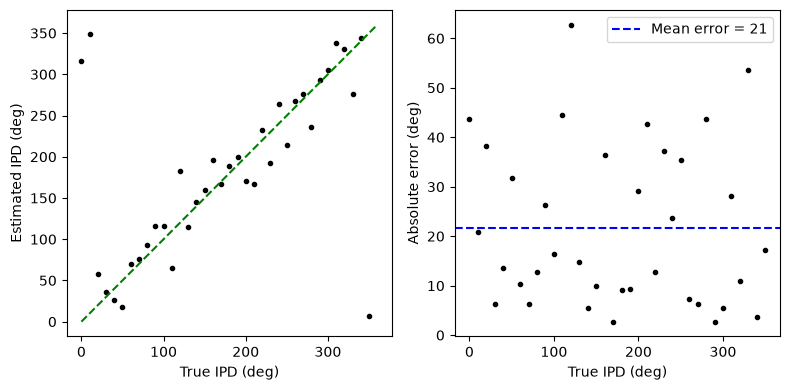

In [5]:


# Mean error should be calculated in a circular fashion
# Giving 359 degrees when the answer is 0 is 1 degree not 359
# So compute +-360 deg and take the minimum
def compute_errors(ipds, ipds_est):
    ipds_est_circ = array([ipds_est, ipds_est+2*pi, ipds_est-2*pi])
    abs_errors_circ = abs(ipds[newaxis, :]-ipds_est_circ)
    abs_errors_deg = amin(abs_errors_circ, axis=0)*180/pi
    return abs_errors_deg


def plot_results(ipds, ipds_est):
    abs_errors_deg = compute_errors(ipds, ipds_est)
    figure(figsize=(8, 4), dpi=100)
    subplot(121)
    plot(ipds*180/pi, ipds_est*180/pi, '.k')
    plot([0, 360], [0, 360], '--g')
    xlabel('True IPD (deg)')
    ylabel('Estimated IPD (deg)')
    subplot(122)
    plot(ipds*180/pi, abs_errors_deg, '.k')
    mean_abs_error_deg = mean(abs_errors_deg)
    axhline(mean_abs_error_deg, ls='--', c='b', label=f'Mean error = {int(mean_abs_error_deg)}')
    xlabel('True IPD (deg)')
    ylabel('Absolute error (deg)')
    legend(loc='best')
    tight_layout();
    
plot_results(ipds, ipds_est)

